# Fase 1 · Etapa 1.3a — Qualidade do canal de força (martelo)

> **Bases de dados usadas:** **dados do pesquisador** — os 144 registros da 2ª campanha
> (canal `Martelo` [N]) e, só para descrição, os 12 da 1ª campanha (canal escolhido por
> maior pulso/ruído, já que C9 continua aberto). Referência externa: fundo de escala do
> martelo (±5 V / 2,25 mV/N ≈ ±2222 N, NI 9234 + PCB 086C03).

Por que importa: a FRF é a/F. O espectro da força define **onde há energia** para medir a
FRF (fora dessa banda, a/F é ruído dividido por quase zero); impactos múltiplos criam
vales no espectro da força e baixam a coerência nessas frequências.

Métricas (`dampid.eda.quality`):
* **pulsos**: trechos contíguos acima de max(5 % do pico, 8σ do ruído), unindo trechos
  separados por < 0,5 ms; o principal é o de maior pico;
* **largura**: tempo acima de 10 % do pico (≈ tempo de contato);
* **banda**: espectro só do pulso principal; f₋₁₀ e f₋₂₀ = primeira frequência em que ele
  cai 10/20 dB abaixo do nível de baixa frequência.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dampid.eda import quality as q
from dampid.io.catalog import load_catalog
from dampid.io.ni_csv import read_ni_csv

cat = load_catalog("data/catalog.yaml")
sv = pd.read_csv("data/processed/fase1_survey.csv")
c2 = sv[sv.campaign == 2].copy()
c2["multi"] = c2.second_pulse_ratio >= 0.10

## 1. Resumo por configuração (2ª campanha)

In [2]:
tab = c2.groupby("config").agg(
    n=("id", "size"),
    pulsos_med=("n_pulses", "median"),
    multiplos_ge10pct=("multi", "sum"),
    razao_2o_pulso_med=("second_pulse_ratio", "median"),
    dt_2o_pulso_ms_med=("second_pulse_dt_ms", "median"),
    largura_ms_med=("F_width_ms", "median"),
    largura_ms_min=("F_width_ms", "min"),
    largura_ms_max=("F_width_ms", "max"),
    pico_N_med=("F_peak_N", "median"),
    f10_med=("F_f10db_hz", "median"),
    f20_med=("F_f20db_hz", "median"),
    pico_sobre_fundo_max=("F_peak_over_fs", "max"),
)
with pd.option_context("display.width", 250):
    print(tab.round(2).to_string())
tab.round(3).to_csv("docs/reports/fase1/03_forca_por_config.csv")

                      n  pulsos_med  multiplos_ge10pct  razao_2o_pulso_med  dt_2o_pulso_ms_med  largura_ms_med  largura_ms_min  largura_ms_max  pico_N_med  f10_med  f20_med  pico_sobre_fundo_max
config                                                                                                                                                                                            
LL_ACO               16         1.0                  2                0.00               13.81            5.64            0.43            5.98       30.84    188.5    299.5                  0.10
LL_ACRILICO          16         3.0                 16                0.90                5.62            2.97            0.47           10.51       19.49    627.0   1062.0                  0.01
LL_AL                16         1.0                  2                0.00               24.08            6.54            6.09            6.84       11.69    157.5    310.0                  0.01
LL_FIB_CARBONO       16  

## 2. Registros fora do padrão da própria configuração
Largura do pulso a mais de 25 % da mediana da configuração, ou pulsos antes do principal.

In [3]:
med_w = c2.groupby("config").F_width_ms.transform("median")
odd = c2[(abs(c2.F_width_ms / med_w - 1) > 0.25) | (c2.pulses_before_main > 0)]
print(odd[["id", "n_pulses", "pulses_before_main", "F_peak_N", "F_width_ms", "F_f10db_hz",
           "second_pulse_ratio", "second_pulse_dt_ms"]].round(2).to_string(index=False))

            id  n_pulses  pulses_before_main  F_peak_N  F_width_ms  F_f10db_hz  second_pulse_ratio  second_pulse_dt_ms
     LL_ACO_10         2                   0     50.56        2.15       466.0                0.28               23.52
     LL_ACO_11         2                   0    225.29        0.43      2392.0                0.35                4.10
LL_ACRILICO_01         3                   1     14.12       10.51        75.0                1.00               -6.21
LL_ACRILICO_02         5                   0     17.73        0.47       708.0                0.71                5.66


## 3. Forma dos pulsos (alinhados no início do pulso principal, normalizados pelo pico)

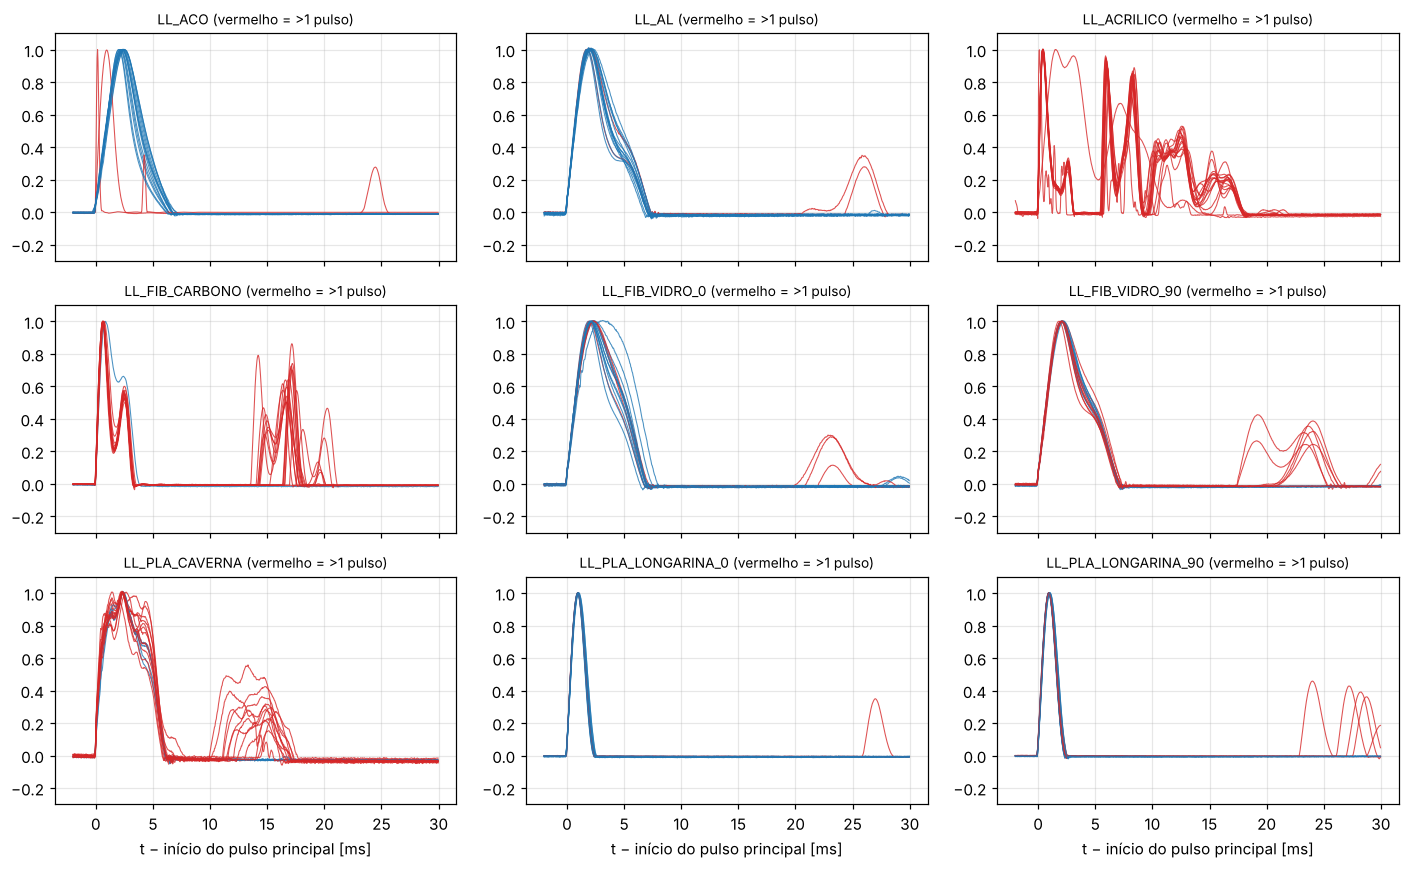

In [4]:
cfgs = ["LL_ACO", "LL_AL", "LL_ACRILICO", "LL_FIB_CARBONO", "LL_FIB_VIDRO_0", "LL_FIB_VIDRO_90",
        "LL_PLA_CAVERNA", "LL_PLA_LONGARINA_0", "LL_PLA_LONGARINA_90"]
spectra = {}
fig, axs = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
for ax, cfg in zip(axs.ravel(), cfgs, strict=True):
    spectra[cfg] = []
    for e in cat.by_config()[cfg]:
        r = read_ni_csv("data/raw/" + e.path)
        fs = r.fs_hz
        F = r.data[2]
        P = q.find_pulses(F, fs)
        p = P[q.main_pulse(P)]
        sl = slice(p.i_start - int(2e-3 * fs), p.i_start + int(30e-3 * fs))
        t = (np.arange(sl.stop - sl.start) - int(2e-3 * fs)) / fs * 1e3
        ax.plot(t, F[sl] / p.peak, lw=0.7, color="C3" if len(P) > 1 else "C0", alpha=0.8)
        bw = q.force_bandwidth(F, fs, p)
        spectra[cfg].append((bw["f"], bw["db"]))
    ax.set_title(f"{cfg} (vermelho = >1 pulso)", fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_ylim(-0.3, 1.1)
for ax in axs[-1]:
    ax.set_xlabel("t − início do pulso principal [ms]")
plt.tight_layout()

## 4. Espectro do pulso principal e banda útil

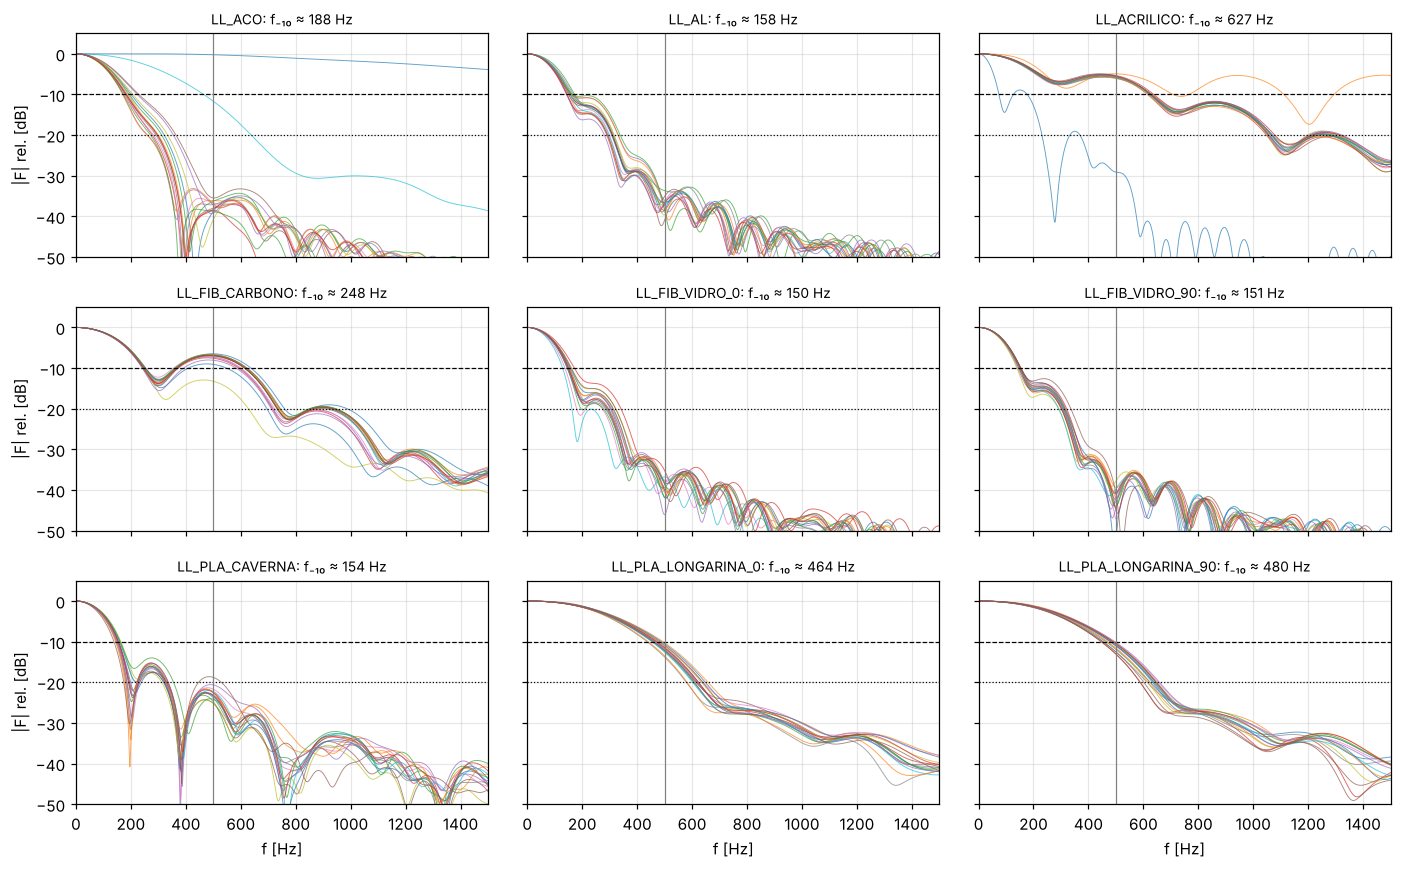

In [5]:
fig, axs = plt.subplots(3, 3, figsize=(13, 8), sharex=True, sharey=True)
for ax, cfg in zip(axs.ravel(), cfgs, strict=True):
    for f, db in spectra[cfg]:
        ax.plot(f, db, lw=0.6, alpha=0.7)
    ax.axhline(-10, color="k", ls="--", lw=0.8)
    ax.axhline(-20, color="k", ls=":", lw=0.8)
    ax.axvline(500, color="gray", lw=0.8)
    ax.set_xlim(0, 1500)
    ax.set_ylim(-50, 5)
    ax.set_title(f"{cfg}: f₋₁₀ ≈ {tab.loc[cfg, 'f10_med']:.0f} Hz", fontsize=9)
    ax.grid(alpha=0.3)
for ax in axs[-1]:
    ax.set_xlabel("f [Hz]")
for ax in axs[:, 0]:
    ax.set_ylabel("|F| rel. [dB]")
plt.tight_layout()

**Nota sobre f₋₂₀.** Para um pulso aproximadamente meio-seno de duração T, o espectro tem
o primeiro zero em 1,5/T. Pulsos longos e simétricos (PLA caverna, T ≈ 5,8 ms → zero em
≈ 260 Hz) cruzam −20 dB logo antes desse zero, e f₋₂₀ cai para ≈ 180–200 Hz; pulsos
assimétricos "enchem" o zero e f₋₂₀ sobe. Por isso f₋₁₀ é o indicador mais estável; a
banda útil de verdade será fixada pela coerência na Fase 2 (D2.3).

## 5. 1ª campanha (descritivo; escala de força desconhecida — C9)

In [6]:
c1 = sv[sv.campaign == 1]
print(c1[["id", "force_channel", "n_pulses", "F_peak_N", "F_width_ms", "F_f10db_hz",
          "second_pulse_ratio"]].round(2).to_string(index=False))

                              id  force_channel  n_pulses  F_peak_N  F_width_ms  F_f10db_hz  second_pulse_ratio
       C1_ACO_CC_mcentro_acentro              2         1     11.70        4.41       223.0                0.00
   C1_ACO_CC_mforacentro_acentro              2         1     12.43        3.36       304.0                0.00
        C1_ACO_CF_mcentro_aponta              1         1     21.43        4.57       372.0                0.00
         C1_ACO_CF_mponta_aponta              1         4     12.78        2.19       436.0                0.75
  C1_ACRILICO_CC_mcentro_acentro              2         1      9.02       14.84        57.0                0.00
C1_ACRILICO_CC_mforaponta_aponta              2         1      6.23       12.97        65.0                0.00
   C1_ACRILICO_CF_mcentro_aponta              1         4      4.61       21.56        43.0                0.13
    C1_ACRILICO_CF_mponta_aponta              2         3     26.70        0.27      3684.0             